### Sales Data Analysis and Data Cleaning Project

This Notebook contains sales_raw_data_dirty_100k.csv and produces a clean dataset ready for analysis.

Problem Statement:

A retail company has collected a large sales dataset containing more than 100,000 records. However, the dataset contains various data quality issues such as:

* Missing values
* Duplicate records
* Duplicate Order IDs
* Mixed date formats
* Inconsistent region values
* Inconsistent payment methods
* Quantity stored as text
* Unit Price stored with currency symbols
* Incorrect TotalSales values

The goal of this project is to clean the dataset, prepare it for analysis, perform exploratory data analysis (EDA), and generate business insights and recommendations.

### 1. Setup & Load

In [2]:
import pandas as pd
import numpy as np

INPUT_FILE = "sales_raw_data_dirty_100k.csv"
OUTPUT_fILE = "sales_clean_data_100k.csv"

df = pd.read_csv(INPUT_FILE)
print("Raw shape:", df.shape)

df.head()

Raw shape: (101500, 15)


,OrderID,OrderDate,CustomerID,CustomerName,Product,Category,Region,Country,Quantity,UnitPrice,DiscountPercent,TotalSales,PaymentMethod,SalesChannel,SalesRep
0,100000,08-17-2023,2041,Aarav Garcia,Coffee Beans,Groceries,Central,USA,4,1106.02,25.0,3535.06,CREDIT CARD,Online,Priya
1,100001,12-Feb-2024,12149,Diya Smith,Rice 5kg,Groceries,central,USA,8,$1215.1,5.0,9234.76,paypal,Online,Rahul
2,100002,02-17-2025,13403,Aarav Garcia,Phone,Electronics,west,Australia,6,1211.66,25.0,5452.47,Net Banking,Distributor,Priya
3,100003,01-29-2024,15857,Diya Smith,Laptop,Electronics,central,Australia,4,1477.91,0.0,5911.64,paypal,Store,NaN
4,100004,06-30-2024,8196,Diya Smith,T-Shirt,Clothing,CENTRAL,USA,9,249.29,NaN,2243.61,COD,Distributor,Anita


### 2. Initial Data Quality Check

Before cleaning the dataset, it is important to assess the quality of the raw data.

The following checks will be performed:

* Dataset dimensions
* Column information
* Missing values
* Duplicate records
* Duplicate Order IDs

This helps identify the extent of cleaning required.

In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values Per Column:")
print(df.isnull().sum())

print("\nExact Duplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Order IDs:")
print(df.duplicated(subset=['OrderID']).sum())

Dataset Shape:
(101500, 15)

Column Names:
['OrderID', 'OrderDate', 'CustomerID', 'CustomerName', 'Product', 'Category', 'Region', 'Country', 'Quantity', 'UnitPrice', 'DiscountPercent', 'TotalSales', 'PaymentMethod', 'SalesChannel', 'SalesRep']

Data Types:
OrderID              int64
OrderDate              str
CustomerID           int64
CustomerName           str
Product                str
Category               str
Region                 str
Country                str
Quantity               str
UnitPrice              str
DiscountPercent    float64
TotalSales         float64
PaymentMethod          str
SalesChannel           str
SalesRep               str
dtype: object

Missing Values Per Column:
OrderID                0
OrderDate              0
CustomerID             0
CustomerName       20322
Product                0
Category               0
Region                 0
Country                0
Quantity               0
UnitPrice              0
DiscountPercent    16967
TotalSales          

In [4]:
df.isnull().sum()

OrderID                0
OrderDate              0
CustomerID             0
CustomerName       20322
Product                0
Category               0
Region                 0
Country                0
Quantity               0
UnitPrice              0
DiscountPercent    16967
TotalSales             0
PaymentMethod          0
SalesChannel           0
SalesRep           16745
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(1500)

In [6]:
df.duplicated(subset=['OrderID']).sum()

np.int64(1500)

### 3. Strip Whitespace From Text Columns

Many text columns may contain unnecessary leading or trailing spaces.

For example:

" Central " " David " " PayPal "

These spaces can cause incorrect grouping and duplicate categories during analysis.

Therefore, whitespace will be removed from all text columns.

In [7]:
# Before Cleaning

print("Region Sample Before Cleaning:")
print(df['Region'].unique()[:20])

print("\nPayment Method Sample Before Cleaning:")
print(df['PaymentMethod'].unique()[:20])

Region Sample Before Cleaning:
<ArrowStringArray>
['Central', 'central',    'west', 'CENTRAL',   'South',    'East',    'EAST',
    'WEST',   'SOUTH',   'south',    'West']
Length: 11, dtype: str

Payment Method Sample Before Cleaning:
<ArrowStringArray>
[     'CREDIT CARD',           'paypal',      'Net Banking',
              'COD',           'PayPal', 'Cash On Delivery',
      'credit card',              'upi',       'Debit Card',
              'UPI']
Length: 10, dtype: str


In [8]:
text_cols = df.select_dtypes(include='object').columns.tolist()

for c in text_cols:
    df[c] = df[c].astype(str).str.strip()
    df[c] = df[c].replace({'nan': np.nan, 'None': np.nan})

print("Stripped columns:", text_cols)

Stripped columns: ['OrderDate', 'CustomerName', 'Product', 'Category', 'Region', 'Country', 'Quantity', 'UnitPrice', 'PaymentMethod', 'SalesChannel', 'SalesRep']


C:\Users\DELL\AppData\Local\Temp\ipykernel_18916\1395323775.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include='object').columns.tolist()


In [9]:
# After Cleaning 

print("Region Sample After Cleaning:")
print(df['Region'].unique()[:20])

print("\nPayment Method Sample After Cleaning:")
print(df['PaymentMethod'].unique()[:20])

Region Sample After Cleaning:
<ArrowStringArray>
['Central', 'central',    'west', 'CENTRAL',   'South',    'East',    'EAST',
    'WEST',   'SOUTH',   'south',    'West']
Length: 11, dtype: str

Payment Method Sample After Cleaning:
<ArrowStringArray>
[     'CREDIT CARD',           'paypal',      'Net Banking',
              'COD',           'PayPal', 'Cash On Delivery',
      'credit card',              'upi',       'Debit Card',
              'UPI']
Length: 10, dtype: str


### 4. Standardize Region

The Region column contains inconsistent values such as:

* CENTRAL
* Central
* central
* WEST
* west
* SOUTH
* south

Although these represent the same regions, they are treated as different values by Python and reporting tools.

To ensure consistency, Region values will be standardized.

In [11]:
# Before Cleaning 

print("Before:")
print(sorted(df['Region'].dropna().unique()))

Before:
['CENTRAL', 'Central', 'EAST', 'East', 'SOUTH', 'South', 'WEST', 'West', 'central', 'south', 'west']


In [12]:
df['Region'] = df['Region'].str.title()

In [13]:
# After Cleaning

print("After:")
print(sorted(df['Region'].dropna().unique()))

After:
['Central', 'East', 'South', 'West']


### 5: Standardize Payment Method

The PaymentMethod column contains inconsistent values due to differences in capitalization and naming conventions.

Examples:

* CREDIT CARD
* credit card
* PayPal
* paypal
* UPI
* upi
* COD
* Cash On Delivery

These values represent the same payment methods but are stored in different formats.

To improve consistency and reporting accuracy, payment methods will be standardized.

In [14]:
# Before Cleaning 

print("Before:")
print(sorted(df['PaymentMethod'].dropna().unique()))

Before:
['COD', 'CREDIT CARD', 'Cash On Delivery', 'Debit Card', 'Net Banking', 'PayPal', 'UPI', 'credit card', 'paypal', 'upi']


In [15]:
pm_map = {
    'credit card': 'Credit Card',
    'debit card': 'Debit Card',
    'paypal': 'PayPal',
    'net banking': 'Net Banking',
    'upi': 'UPI',
    'cash on delivery': 'Cash On Delivery',
    'cod': 'Cash On Delivery'
}

df['PaymentMethod'] = (
    df['PaymentMethod']
    .str.lower()
    .map(pm_map)
    .fillna(df['PaymentMethod']))

In [16]:
# After Cleaning 

print("After:")
print(sorted(df['PaymentMethod'].dropna().unique()))

After:
['Cash On Delivery', 'Credit Card', 'Debit Card', 'Net Banking', 'PayPal', 'UPI']


### 6. Clean Quantity Column

The Quantity column contains values stored as text.

Examples:

* 8 pcs
* 4 pcs
* 10 pcs

These values cannot be used directly in mathematical calculations.

The objective is to remove the text portion and convert Quantity into a numeric data type.

In [17]:
# Before Cleaning

print("Quantity Sample Before Cleaning:")

print(df['Quantity'].head(20))

Quantity Sample Before Cleaning:
0         4
1         8
2         6
3         4
4         9
5        10
6         6
7         5
8         5
9     8 pcs
10    9 pcs
11    4 pcs
12        8
13        7
14        8
15    1 pcs
16    1 pcs
17       10
18        5
19        6
Name: Quantity, dtype: str


In [18]:
df['Quantity'] = (
    df['Quantity']
    .astype(str)
    .str.replace(r'\s*pcs', '',
                 regex=True)
)

df['Quantity'] = pd.to_numeric(
    df['Quantity'],
    errors='coerce'
)

df['Quantity'].describe()

count    101500.000000
mean          5.510985
std           2.864636
min           1.000000
25%           3.000000
50%           6.000000
75%           8.000000
max          10.000000
Name: Quantity, dtype: float64

In [19]:
# After Cleaning

print("Quantity Sample After Cleaning:")

print(df['Quantity'].head(20))

Quantity Sample After Cleaning:
0      4
1      8
2      6
3      4
4      9
5     10
6      6
7      5
8      5
9      8
10     9
11     4
12     8
13     7
14     8
15     1
16     1
17    10
18     5
19     6
Name: Quantity, dtype: int64


### 7. Clean UnitPrice Column

The UnitPrice column contains monetary values.

Some records include the dollar ($) symbol while others are stored as plain numeric values.

Examples:

* $1215.10

* $450.50

* 1106.02

For numerical analysis and calculations, the UnitPrice column must be converted into a consistent numeric format.

In [20]:
# Before Cleaning

print("UnitPrice Sample Before Cleaning:")

print(df['UnitPrice'].head(20))

UnitPrice Sample Before Cleaning:
0      1106.02
1      $1215.1
2      1211.66
3      1477.91
4       249.29
5       475.44
6      1496.32
7     $1291.87
8      1144.13
9       1394.0
10      793.87
11       36.45
12      202.81
13     1094.97
14     1385.28
15        8.22
16       717.8
17      893.81
18     1393.88
19      660.09
Name: UnitPrice, dtype: str


In [21]:
df['UnitPrice'] = (
    df['UnitPrice']
    .astype(str)
    .str.replace('$', '',
                 regex=False)
)

df['UnitPrice'] = pd.to_numeric(
    df['UnitPrice'],
    errors='coerce'
)

df['UnitPrice'].describe()

count    101500.000000
mean        752.646140
std         431.815017
min           5.020000
25%         379.335000
50%         753.740000
75%        1126.415000
max        1499.980000
Name: UnitPrice, dtype: float64

In [22]:
# After Cleaning

print("UnitPrice Sample After Cleaning:")

print(df['UnitPrice'].head(20))

UnitPrice Sample After Cleaning:
0     1106.02
1     1215.10
2     1211.66
3     1477.91
4      249.29
5      475.44
6     1496.32
7     1291.87
8     1144.13
9     1394.00
10     793.87
11      36.45
12     202.81
13    1094.97
14    1385.28
15       8.22
16     717.80
17     893.81
18    1393.88
19     660.09
Name: UnitPrice, dtype: float64


### 8. Parse OrderDate

The OrderDate column contains multiple date formats.

Examples:

* 08-17-2023
* 12-Feb-2024
* 2025-02-17
* 15/06/2024

These inconsistent formats make date analysis difficult.

The objective is to convert all dates into a standard datetime format.

In [23]:
# Before Cleaning

print("OrderDate Sample Before Cleaning:")

print(df['OrderDate'].head(20))

OrderDate Sample Before Cleaning:
0      08-17-2023
1     12-Feb-2024
2      02-17-2025
3      01-29-2024
4      06-30-2024
5      07-02-2024
6     12-Apr-2026
7     20-Feb-2025
8     20-Nov-2023
9      01-09-2026
10     15/09/2023
11     07-13-2025
12     18/11/2025
13     2025-06-01
14     14/05/2025
15     12/09/2025
16     04-01-2026
17    26-Apr-2024
18    27-Jun-2024
19     12-15-2024
Name: OrderDate, dtype: str


In [24]:
def parse_date(d):
    
    if pd.isna(d):
        return pd.NaT

    d = str(d).strip()

    formats = [
        '%m-%d-%Y',
        '%d/%m/%Y',
        '%Y-%m-%d',
        '%Y/%m/%d',
        '%d-%b-%Y'
    ]

    for fmt in formats:
        try:
            return pd.to_datetime(
                d,
                format=fmt
            )
        except ValueError:
            continue

    return pd.NaT

df['OrderDate'] = df['OrderDate'].apply(parse_date)

print(
    "Rows with unparseable/missing dates:",
    df['OrderDate'].isna().sum()
)

Rows with unparseable/missing dates: 0


In [25]:
# After Cleaning

print("OrderDate Sample After Cleaning:")

print(df['OrderDate'].head(20))

OrderDate Sample After Cleaning:
0    2023-08-17
1    2024-02-12
2    2025-02-17
3    2024-01-29
4    2024-06-30
5    2024-07-02
6    2026-04-12
7    2025-02-20
8    2023-11-20
9    2026-01-09
10   2023-09-15
11   2025-07-13
12   2025-11-18
13   2025-06-01
14   2025-05-14
15   2025-09-12
16   2026-04-01
17   2024-04-26
18   2024-06-27
19   2024-12-15
Name: OrderDate, dtype: datetime64[us]


In [27]:
df['OrderDate'].isna().sum()

np.int64(0)

### 9. Recalculate TotalSales

According to the business requirement:

TotalSales should be calculated using:

Quantity × UnitPrice × (1 - DiscountPercent / 100)

Some records may contain incorrect TotalSales values.

To ensure consistency and accuracy, TotalSales will be recalculated.

In [28]:
# Before Cleaning

print("TotalSales Sample Before Recalculation:")

print(
    df[
        ['Quantity',
         'UnitPrice',
         'DiscountPercent',
         'TotalSales']
    ].head(10)
)

TotalSales Sample Before Recalculation:
   Quantity  UnitPrice  DiscountPercent  TotalSales
0         4    1106.02             25.0     3535.06
1         8    1215.10              5.0     9234.76
2         6    1211.66             25.0     5452.47
3         4    1477.91              0.0     5911.64
4         9     249.29              NaN     2243.61
5        10     475.44             15.0     4041.24
6         6    1496.32              0.0     8977.92
7         5    1291.87              NaN     6459.35
8         5    1144.13              0.0     5720.65
9         8    1394.00             10.0    10036.80


In [29]:
df['DiscountPercent'] = (
    df['DiscountPercent']
    .fillna(0)
)

df['TotalSales'] = (
    df['Quantity']
    * df['UnitPrice']
    * (1 - df['DiscountPercent'] / 100)
).round(2)

In [30]:
# After Cleaning

print("TotalSales Sample After Recalculation:")

print(
    df[
        ['Quantity',
         'UnitPrice',
         'DiscountPercent',
         'TotalSales']
    ].head(10)
)

TotalSales Sample After Recalculation:
   Quantity  UnitPrice  DiscountPercent  TotalSales
0         4    1106.02             25.0     3318.06
1         8    1215.10              5.0     9234.76
2         6    1211.66             25.0     5452.47
3         4    1477.91              0.0     5911.64
4         9     249.29              0.0     2243.61
5        10     475.44             15.0     4041.24
6         6    1496.32              0.0     8977.92
7         5    1291.87              0.0     6459.35
8         5    1144.13              0.0     5720.65
9         8    1394.00             10.0    10036.80


### 10. Handle Missing Categorical Values

The dataset contains missing values in categorical columns such as:

* CustomerName
* SalesRep

Removing these rows would result in the loss of valuable sales information.

Instead, missing values will be replaced with a placeholder value called "Unknown".

In [31]:
# Before Cleaning

print("Missing Values Before Cleaning:")

print(
    df[
        ['CustomerName',
         'SalesRep']
    ].isnull().sum()
)

Missing Values Before Cleaning:
CustomerName    20322
SalesRep        16745
dtype: int64


In [32]:
for c in [
    'CustomerName',
    'SalesRep'
]:
    
    df[c] = df[c].fillna('Unknown')

In [33]:
# After Cleaning

print("Missing Values After Cleaning:")

print(
    df[
        ['CustomerName',
         'SalesRep']
    ].isnull().sum()
)

Missing Values After Cleaning:
CustomerName    0
SalesRep        0
dtype: int64


### 11. Remove Exact Duplicate Rows

The initial data quality check identified duplicate records in the dataset.

Duplicate records can lead to:

* Incorrect reporting
* Double-counting of sales
* Inaccurate business insights

Therefore, exact duplicate rows will be removed.

In [34]:
# Before Cleaning

print("Duplicate Rows Before Cleaning:")

print(df.duplicated().sum())

Duplicate Rows Before Cleaning:
1500


In [35]:
before = len(df)

df = df.drop_duplicates()

print(
    "Dropped",
    before - len(df),
    "exact duplicate rows"
)

Dropped 1500 exact duplicate rows


In [36]:
# After Cleaning

print("Duplicate Rows After Cleaning:")

print(df.duplicated().sum())

Duplicate Rows After Cleaning:
0


### 12. Remove Duplicate Order IDs

Each OrderID should uniquely identify a sales transaction.

Duplicate Order IDs may indicate repeated transactions or data entry issues.

To ensure uniqueness, duplicate Order IDs will be removed while keeping the first occurrence.

In [37]:
# Before Cleaning

print("Duplicate Order IDs Before Cleaning:")

print(
    df.duplicated(
        subset=['OrderID']
    ).sum()
)

Duplicate Order IDs Before Cleaning:
0


In [38]:
before = len(df)

df = df.drop_duplicates(
    subset=['OrderID'],
    keep='first'
)

print(
    "Dropped",
    before - len(df),
    "rows with duplicate OrderID"
)

Dropped 0 rows with duplicate OrderID


### 13. Final Data Quality Validation

A final validation is performed to ensure that:

* Missing values have been handled
* Duplicate rows have been removed
* Duplicate Order IDs have been removed
* The dataset is ready for analysis

In [40]:
print("Final Shape:")
print(df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

print(
    "\nRemaining Duplicate Rows:",
    df.duplicated().sum()
)

print(
    "\nRemaining Duplicate OrderIDs:",
    df.duplicated(subset=['OrderID']).sum()
)

Final Shape:
(100000, 15)

Remaining Missing Values:
OrderID            0
OrderDate          0
CustomerID         0
CustomerName       0
Product            0
Category           0
Region             0
Country            0
Quantity           0
UnitPrice          0
DiscountPercent    0
TotalSales         0
PaymentMethod      0
SalesChannel       0
SalesRep           0
dtype: int64

Remaining Duplicate Rows: 0

Remaining Duplicate OrderIDs: 0


### 14. Export Clean Dataset

The cleaned dataset will be exported as a new CSV file.

This file will be used for:

* Data Analysis
* Dashboard Development
* Power BI Reporting
* GitHub Portfolio Projects

In [41]:
OUTPUT_FILE = "sales_clean_data_100k.csv"

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    f"Clean data saved to {OUTPUT_FILE}"
)

print(
    f"Rows: {df.shape[0]}"
)

print(
    f"Columns: {df.shape[1]}"
)

Clean data saved to sales_clean_data_100k.csv
Rows: 100000
Columns: 15


### 15. Exploratory Data Analysis (EDA)

After cleaning the dataset, exploratory data analysis is performed to understand sales patterns, customer behavior, product performance, and regional trends.

EDA helps transform raw data into meaningful business insights.

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')

### 15.1 Summary Statistics

Summary statistics provide an overview of the numerical columns in the dataset.

The analysis includes:

* Count
* Mean
* Standard Deviation
* Minimum
* Maximum
* Quartiles

These metrics help understand the overall distribution of the data.

In [44]:
df.describe()

,OrderID,OrderDate,CustomerID,Quantity,UnitPrice,DiscountPercent,TotalSales
count,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,149999.500000,2024-08-23 03:26:52.223999,10487.848000,5.510460,752.466382,9.205300,3768.978978
min,100000.000000,2023-01-01 00:00:00,1000.000000,1.000000,5.020000,0.000000,4.540000
25%,124999.750000,2023-10-29 00:00:00,5738.000000,3.000000,379.065000,0.000000,1172.157500
50%,149999.500000,2024-08-22 00:00:00,10496.000000,6.000000,753.535000,10.000000,2873.830000
75%,174999.250000,2025-06-18 00:00:00,15221.000000,8.000000,1126.602500,15.000000,5651.375000
max,199999.000000,2026-04-15 00:00:00,20000.000000,10.000000,1499.980000,25.000000,14990.600000
std,28867.657797,NaN,5483.782404,2.864663,431.960674,8.880976,3162.682149


### 15.2 Sales Distribution

This visualization shows how TotalSales values are distributed across all transactions.

The objective is to understand common sales values and identify any concentration of high-value transactions.

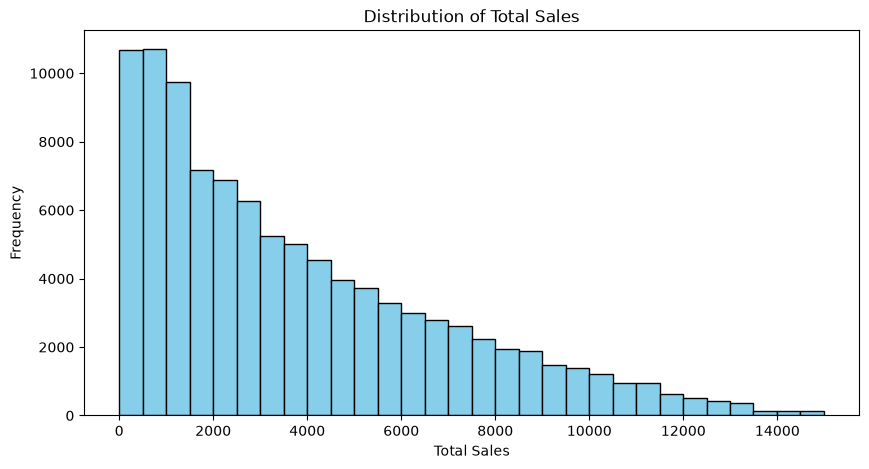

In [45]:
plt.figure(figsize=(10,5))

plt.hist(
    df['TotalSales'],
    bins=30,
    color='skyblue',
    edgecolor='black'
)

plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")

plt.show()

### 15.3 Top 10 Products by Sales

This analysis identifies the products generating the highest revenue.

Product
Phone           42641211.67
Coffee Beans    42455232.08
Dress           42124071.48
Tablet          42000849.81
Sweater         41845292.32
Laptop          41831136.86
Rice 5kg        41522774.84
T-Shirt         41427324.82
Headphones      41050003.93
Name: TotalSales, dtype: float64


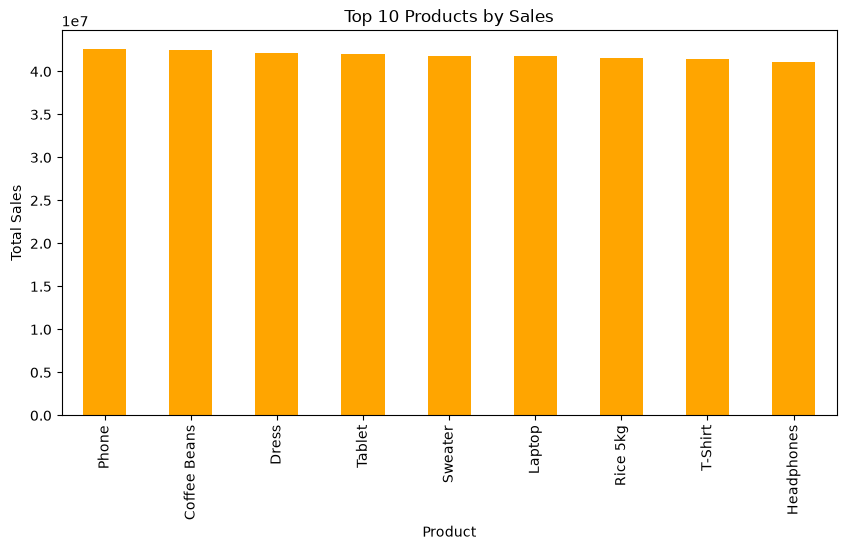

In [46]:
top_products = (
    df.groupby('Product')['TotalSales']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_products)

plt.figure(figsize=(10,5))

top_products.plot(
    kind='bar',
    color='orange'
)

plt.title("Top 10 Products by Sales")
plt.ylabel("Total Sales")

plt.show()

### 15.4 Sales by Category

This analysis evaluates revenue contributions from each product category.

Category
Electronics    1.675232e+08
Clothing       1.253967e+08
Groceries      8.397801e+07
Name: TotalSales, dtype: float64


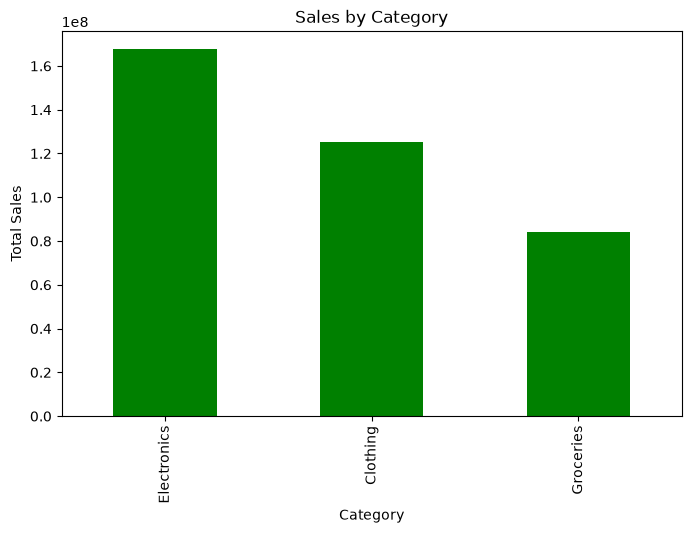

In [47]:
category_sales = (
    df.groupby('Category')['TotalSales']
      .sum()
      .sort_values(ascending=False)
)

print(category_sales)

plt.figure(figsize=(8,5))

category_sales.plot(
    kind='bar',
    color='green'
)

plt.title("Sales by Category")
plt.ylabel("Total Sales")

plt.show()

### 15.5 Sales by Region

This analysis identifies which regions contribute the highest revenue.

Region
Central    1.041771e+08
South      1.027644e+08
West       1.007016e+08
East       6.925480e+07
Name: TotalSales, dtype: float64


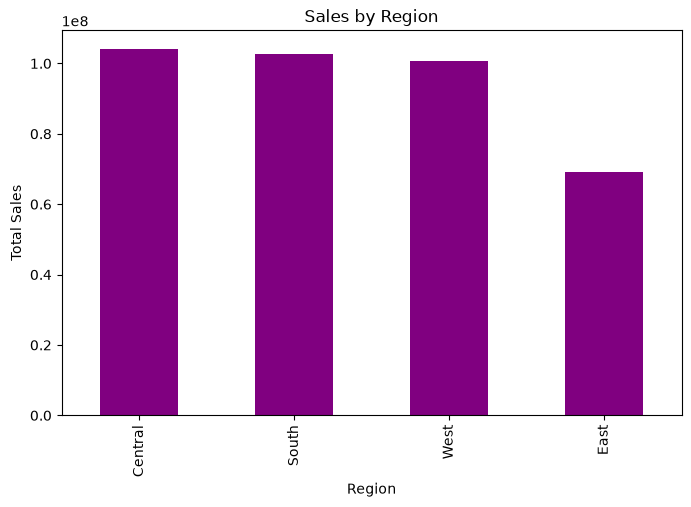

In [48]:
region_sales = (
    df.groupby('Region')['TotalSales']
      .sum()
      .sort_values(ascending=False)
)

print(region_sales)

plt.figure(figsize=(8,5))

region_sales.plot(
    kind='bar',
    color='purple'
)

plt.title("Sales by Region")
plt.ylabel("Total Sales")

plt.show()

### Business Insight

Central is the highest-performing region and should continue receiving strong operational support.

East generated comparatively lower revenue and may represent a growth opportunity through targeted marketing initiatives, customer acquisition strategies, and regional expansion efforts.

### 15.6 Sales by Payment Method

This analysis evaluates customer payment preferences and identifies the payment methods contributing the highest sales revenue.

PaymentMethod
PayPal              76256267.63
Cash On Delivery    75143927.17
UPI                 75130077.74
Credit Card         74536370.70
Debit Card          37942338.32
Net Banking         37888916.25
Name: TotalSales, dtype: float64


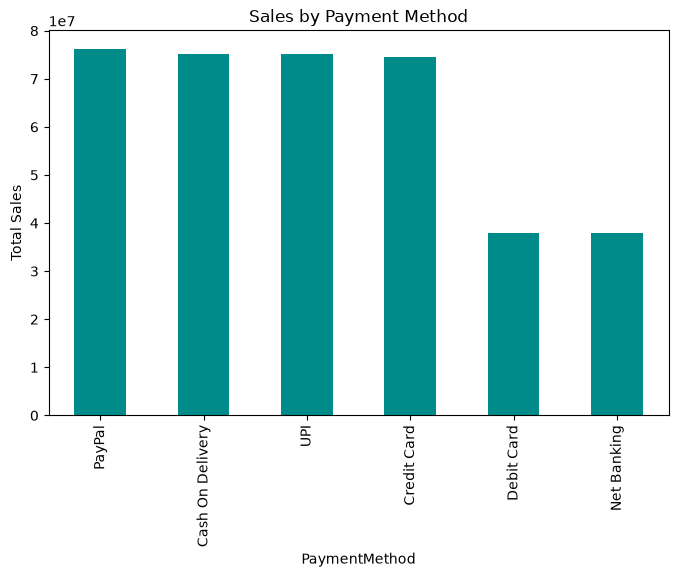

In [49]:
payment_sales = (
    df.groupby('PaymentMethod')['TotalSales']
      .sum()
      .sort_values(ascending=False)
)

print(payment_sales)

plt.figure(figsize=(8,5))

payment_sales.plot(
    kind='bar',
    color='darkcyan'
)

plt.title("Sales by Payment Method")
plt.ylabel("Total Sales")

plt.show()

### 15.7 Sales by Sales Channel

This analysis examines the contribution of each sales channel to total revenue.

SalesChannel
Online         94487426.03
Mobile         94470144.02
Distributor    94136062.61
Store          93804265.15
Name: TotalSales, dtype: float64


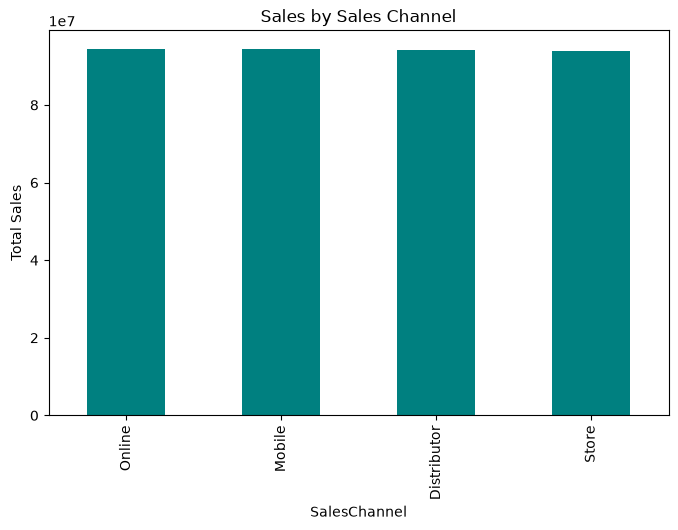

In [50]:
channel_sales = (
    df.groupby('SalesChannel')['TotalSales']
      .sum()
      .sort_values(ascending=False)
)

print(channel_sales)

plt.figure(figsize=(8,5))

channel_sales.plot(
    kind='bar',
    color='teal'
)

plt.title("Sales by Sales Channel")
plt.ylabel("Total Sales")

plt.show()

### 15.8 Monthly Sales Trend

In [51]:
df['Month'] = df['OrderDate'].dt.to_period('M')

Month
2023-01     9800888.30
2023-02     8255418.68
2023-03     9823082.09
2023-04     9115108.78
2023-05     9375805.00
2023-06     9480649.78
2023-07     9803446.16
2023-08     9973679.38
2023-09     9627066.45
2023-10     9370275.09
2023-11     9494304.01
2023-12     9885301.97
2024-01    10048489.27
2024-02     8778664.43
2024-03     9687828.02
2024-04     9121111.12
2024-05     9807136.59
2024-06     9943106.49
2024-07     9882001.40
2024-08     9724696.96
2024-09     9337210.97
2024-10     9818709.68
2024-11     9618144.48
2024-12    10124493.16
2025-01     9649203.03
2025-02     8409683.85
2025-03     9759354.45
2025-04     9560173.93
2025-05     9823593.29
2025-06     9281897.61
2025-07     9521857.40
2025-08    10048221.68
2025-09     9222416.20
2025-10     9320405.20
2025-11     9589807.17
2025-12    10055494.43
2026-01     9283284.10
2026-02     8867080.33
2026-03     9811033.32
2026-04     4797773.56
Freq: M, Name: TotalSales, dtype: float64


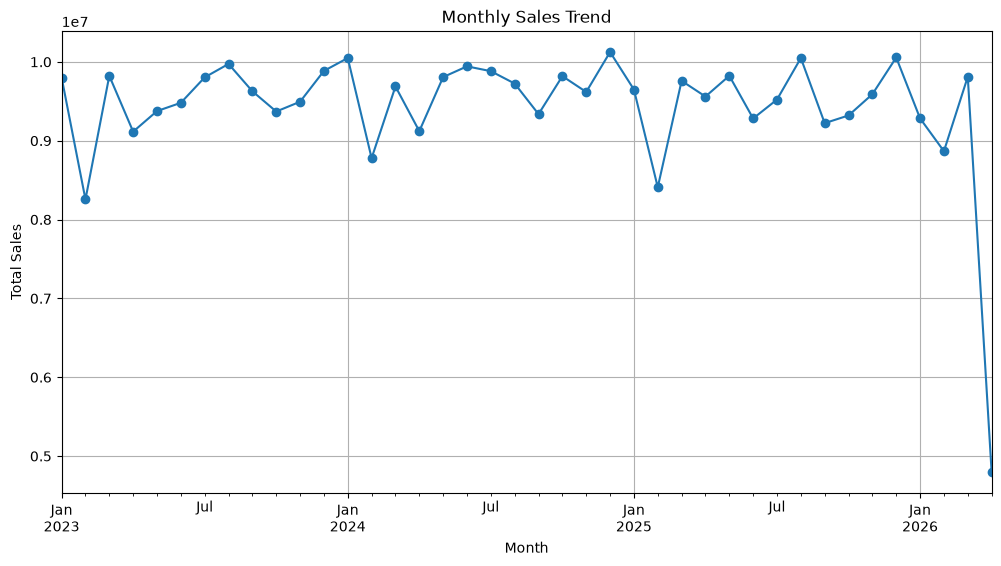

In [52]:
monthly_sales = (
    df.groupby('Month')['TotalSales']
      .sum()
)

print(monthly_sales)

plt.figure(figsize=(12,6))

monthly_sales.plot(
    kind='line',
    marker='o'
)

plt.title("Monthly Sales Trend")
plt.ylabel("Total Sales")

plt.xlabel("Month")

plt.grid(True)

plt.show()

### 15.9 Correlation Analysis

Correlation analysis helps identify relationships between key numerical variables.

The analysis includes:

* Quantity
* UnitPrice
* DiscountPercent
* TotalSales

Correlation values range from:

* +1 : Strong Positive Relationship
* 0 : No Relationship
* -1 : Strong Negative Relationship

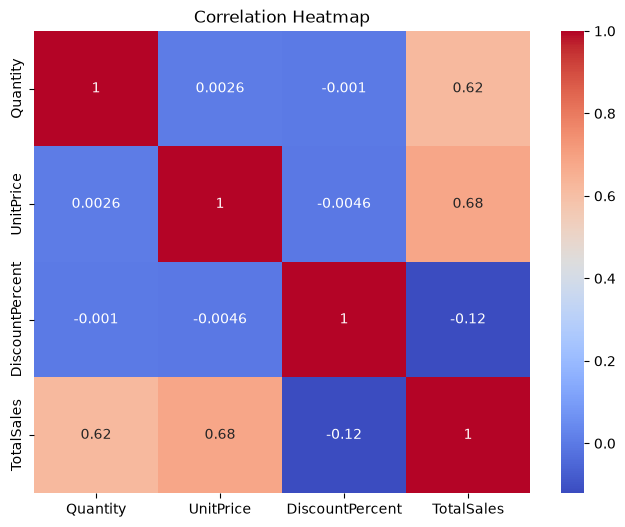

In [53]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[
        [
            'Quantity',
            'UnitPrice',
            'DiscountPercent',
            'TotalSales'
        ]
    ].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

### 16. Final Conclusions

The sales dataset was successfully cleaned, transformed, and analyzed.

Key Findings:

1. Electronics generated the highest revenue among all categories.

2. Phone was the highest revenue-generating product.

3. Central region generated the highest sales revenue.

4. PayPal was the most frequently used high-performing payment method.

5. Revenue was distributed evenly across all sales channels.

6. Monthly sales remained stable throughout the analysis period.

7. The dataset was successfully cleaned, resulting in:

* 0 Missing Values
* 0 Duplicate Rows
* 0 Duplicate Order IDs

The cleaned dataset is suitable for reporting, dashboard creation, and business decision-making.

### 17. Recommendations

Based on the analysis, the following recommendations are suggested:

1. Increase investment in Electronics products due to their strong revenue performance.

2. Prioritize inventory management for high-performing products such as Phones.

3. Continue supporting strong-performing regions such as Central and South.

4. Improve marketing efforts in the East region to increase regional sales.

5. Promote digital payment methods to improve customer convenience and transaction efficiency.

6. Maintain investment across all sales channels because revenue distribution is well balanced.

7. Use monthly sales trends for demand forecasting and inventory planning.

### 18. Project Completion Summary

Project Name: Sales Data Analysis and Data Cleaning Project

Dataset Size: 100,000 Records

Tools Used:

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Jupyter Notebook
* Project Deliverables:

✅ Clean Dataset

✅ Data Quality Assessment

✅ Data Cleaning Documentation

✅ Exploratory Data Analysis

✅ Business Insights

✅ Recommendations

✅ Power BI Dashboard (Next Phase)

✅ GitHub Portfolio Project